# Phase 2 — TF-IDF baseline classifiers

**Medical Document Assistant · Machine Learning**

This notebook reviews the completed Logistic Regression, Linear SVM, and Random Forest experiment on the real Phase 1 openFDA corpus. It covers the frozen group-separated split, training-only cross-validation, validation-based model selection, held-out metrics, confusion matrices, source-linked errors, and saved-model usage.

Run `python -m medical_doc_assistant phase2` first. This notebook reads the recorded experiment and demonstrates inference; it does not retrain the models or change their selection. It can run offline with the local data/models.

As specified in the original plan, this project is informational only and is not medical advice.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from medical_doc_assistant.baseline import classify_text, load_baseline
from medical_doc_assistant.storage import write_json

ROOT = Path.cwd()
if not (ROOT / 'configs' / 'phase2.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'configs' / 'phase2.json').exists(), 'Open the notebook from the project or notebooks folder.'
REPORTS = ROOT / 'reports' / 'phase2'
assert (REPORTS / 'run_manifest.json').exists(), 'Run python -m medical_doc_assistant phase2 first.'
run = json.loads((REPORTS / 'run_manifest.json').read_text(encoding='utf-8'))
split = json.loads((REPORTS / 'split_manifest.json').read_text(encoding='utf-8'))
config = json.loads((ROOT / 'configs' / 'phase2.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(REPORTS / 'model_comparison.csv')
selected = run['selected_model']
pd.set_option('display.max_colwidth', 90)
print(f'Python {sys.version.split()[0]} | selected benchmark: {selected}')

Python 3.10.6 | selected benchmark: random_forest


## 1. Frozen train / validation / test data

All 2,471 cleaned Phase 1 documents are retained. Whole ingredient components are allocated to approximately 70% / 15% / 15%, with all six target classes represented in each partition. The saved record assignments will also be used for later neural models.

In [2]:
assignments = pd.read_csv(ROOT / 'data' / 'splits' / 'phase2_split.csv')
sizes = assignments.groupby('split').agg(documents=('record_id', 'size'), groups=('benchmark_group_id', 'nunique'))
display(sizes.reindex(['train', 'validation', 'test']))
display(pd.read_csv(REPORTS / 'split_class_balance.csv'))
assert assignments.groupby('benchmark_group_id')['split'].nunique().eq(1).all()
print('Dataset SHA-256:', split['dataset_sha256'])
print('Frozen split SHA-256:', split['split_sha256'])

,documents,groups
split,,
train,1762,67
validation,367,18
test,342,15


,split,class_label,documents,groups
0,test,acid_reducer,19,2
1,test,anti_inflammatory_nsaid,64,2
2,test,antibacterial,69,5
3,test,antifungal,69,2
4,test,antihypertensive,57,3
5,test,corticosteroid,64,2
6,train,acid_reducer,235,3
7,train,anti_inflammatory_nsaid,348,9
8,train,antibacterial,319,25
9,train,antifungal,298,13


Dataset SHA-256: 3eadaed552f771aae883df674eed9efc38f0cebf86c355041e3bda350e85f23c
Frozen split SHA-256: 9b41f3cf3e5539efa8905b0db37f45ff0abd03b62bd1adf65d05e54630fb389c


## 2. Ingredient aliases and duplicate audit

Phase 1 groups are preserved. Exact/normalized RxNorm ingredient (IN) relationships add edges for source-name variants such as salts. Ambiguous matches remain unmapped. A fixed hashed word-5-gram representation audits very similar cross-component documents before splitting. This representation has no learned vocabulary/IDF and is used only for evaluation grouping.

The thresholded audit does not establish that every chemical synonym or semantic near-duplicate has been resolved.

In [3]:
display(pd.Series(split['grouping_audit'], name='grouping_audit'))
matches = pd.read_csv(REPORTS / 'rxnorm_matches.csv', keep_default_na=False)
display(matches.loc[matches.source_name.str.contains('CIPROFLOXACIN|DOXYCYCLINE|ESOMEPRAZOLE')])
print('Additional qualifying text pairs:', len(pd.read_csv(REPORTS / 'near_duplicate_pairs.csv')))

phase1_groups                   105
groups_after_rxnorm             100
rxnorm_version          05-Oct-2026
rxnorm_names_matched            251
rxnorm_names_total              259
benchmark_groups                100
near_duplicate_pairs              0
similarity_threshold          0.985
Name: grouping_audit, dtype: object

,source_name,status,ingredient_rxcui,ingredient_name
57,CIPROFLOXACIN,matched,2551,ciprofloxacin
58,CIPROFLOXACIN HYDROCHLORIDE,matched,2551,ciprofloxacin
82,DOXYCYCLINE,matched,3640,doxycycline
83,DOXYCYCLINE HYCLATE,matched,3640,doxycycline
87,ESOMEPRAZOLE,matched,283742,esomeprazole
88,ESOMEPRAZOLE MAGNESIUM,matched,283742,esomeprazole
89,ESOMEPRAZOLE MAGNESIUM TRIHYDRATE,matched,283742,esomeprazole


Additional qualifying text pairs: 0


## 3. TF-IDF feature pipeline

`document_text` is the sole classifier input. TF-IDF vocabulary and IDF are fit inside each training CV fit fold. Final pipelines are refit on train + validation after model selection. Group IDs, URLs, class metadata, and test text are not feature inputs. The code is in `src/medical_doc_assistant/baseline.py`.

In [4]:
display(pd.Series(config['tfidf'], name='TF-IDF settings'))
display(comparison[['display_name', 'best_parameters', 'features', 'search_seconds', 'final_fit_seconds']])
print('Final artifact fitted partitions: train + validation')

ngram_range     [1, 2]
min_df               2
max_df            0.99
max_features     30000
sublinear_tf      True
lowercase         True
Name: TF-IDF settings, dtype: object

,display_name,best_parameters,features,search_seconds,final_fit_seconds
0,Logistic Regression,"{""classifier__C"": 8.0}",30000,42.718906,9.521699
1,Linear SVM,"{""classifier__C"": 4.0}",30000,30.599417,2.653609
2,Random Forest,"{""classifier__max_depth"": 40, ""classifier__min_samples_leaf"": 2}",30000,38.596019,2.107347


Final artifact fitted partitions: train + validation


## 4. Training-only group-aware cross-validation

Ten configurations are compared across three fixed training CV folds. Family hyperparameters are selected by macro F1 over all six labels. Whole ingredient components remain intact, so fold sizes and class supports can be uneven. CV standard deviation describes fold-to-fold variation, not a confidence interval.

In [5]:
cv = pd.read_csv(REPORTS / 'cv_results.csv')
display(cv[['model', 'parameters', 'rank_macro_f1', 'macro_f1_mean', 'macro_f1_std', 'fold_0_macro_f1', 'fold_1_macro_f1', 'fold_2_macro_f1']])
folds = pd.read_csv(REPORTS / 'cv_class_balance.csv')
display(folds.loc[folds['subset'].eq('validation')].pivot(index='class_label', columns='fold', values='documents'))

,model,parameters,rank_macro_f1,macro_f1_mean,macro_f1_std,fold_0_macro_f1,fold_1_macro_f1,fold_2_macro_f1
0,logistic_regression,"{""classifier__C"": 0.5}",2,0.644980,0.066744,0.550807,0.697624,0.686507
1,logistic_regression,"{""classifier__C"": 2.0}",3,0.640584,0.061577,0.554330,0.673336,0.694087
2,logistic_regression,"{""classifier__C"": 8.0}",1,0.649241,0.070347,0.549756,0.698624,0.699343
3,linear_svm,"{""classifier__C"": 0.25}",3,0.664076,0.077382,0.556193,0.733923,0.702112
4,linear_svm,"{""classifier__C"": 1.0}",2,0.728468,0.155809,0.555155,0.697281,0.932967
5,linear_svm,"{""classifier__C"": 4.0}",1,0.747237,0.154652,0.554352,0.754392,0.932967
6,random_forest,"{""classifier__max_depth"": 40, ""classifier__min_samples_leaf"": 1}",3,0.726321,0.131178,0.548332,0.770021,0.860608
7,random_forest,"{""classifier__max_depth"": 40, ""classifier__min_samples_leaf"": 2}",1,0.743614,0.134396,0.558327,0.799580,0.872935
8,random_forest,"{""classifier__max_depth"": null, ""classifier__min_samples_leaf"": 1}",3,0.726321,0.131178,0.548332,0.770021,0.860608
9,random_forest,"{""classifier__max_depth"": null, ""classifier__min_samples_leaf"": 2}",1,0.743614,0.134396,0.558327,0.799580,0.872935


fold,0,1,2
class_label,,,
acid_reducer,118,115,2
anti_inflammatory_nsaid,330,9,9
antibacterial,106,104,109
antifungal,219,52,27
antihypertensive,22,79,165
corticosteroid,239,41,16


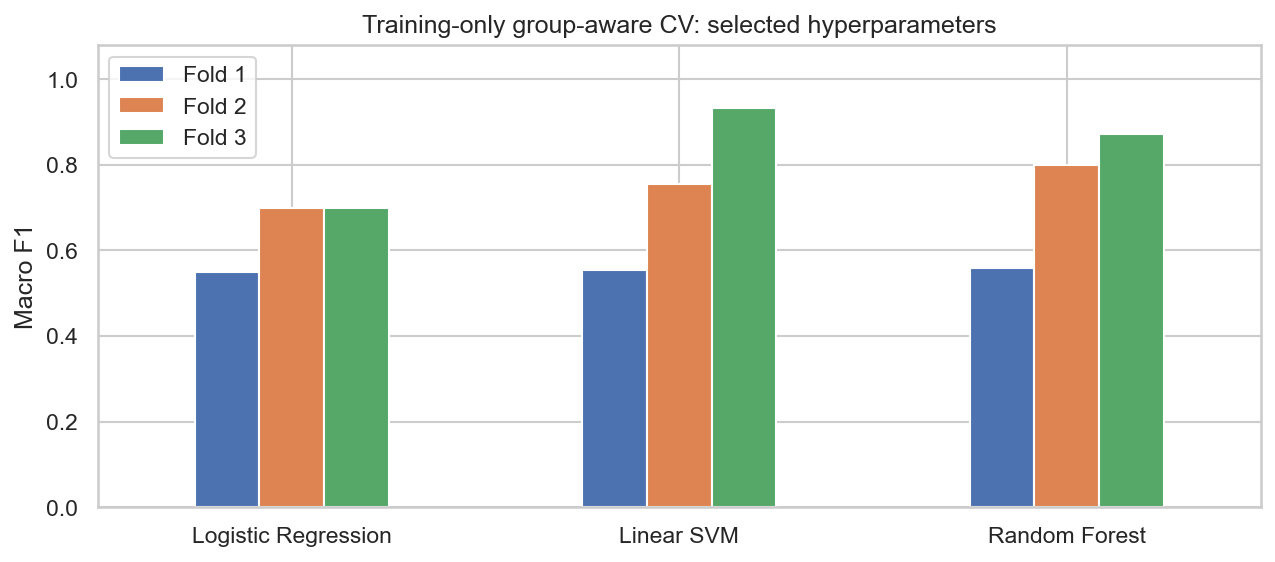

In [6]:
display(Image(filename=str(REPORTS / 'figures' / 'cv_fold_scores.png')))

## 5. Validation-based model selection

Each tuned model is evaluated on the separate validation partition. The winner is chosen by validation macro F1, with training CV macro F1 and a fixed family order as tie-breaks. This decision is saved before test prediction. All three frozen candidates are then refit on train + validation for their final artifacts.

In [7]:
selection = json.loads((REPORTS / 'model_selection.json').read_text(encoding='utf-8'))
display(pd.DataFrame(selection['validation_results'])[['display_name', 'cv_macro_f1_mean', 'validation_accuracy', 'validation_macro_f1']])
print('Selected:', selection['selected_model'])
print('Selected at:', selection['selected_at_utc'])
print('Test evaluation started:', run['test_evaluation_started_at_utc'])
assert selection['test_used_for_selection'] is False

,display_name,cv_macro_f1_mean,validation_accuracy,validation_macro_f1
0,Logistic Regression,0.649241,0.855586,0.835485
1,Linear SVM,0.747237,0.869210,0.856522
2,Random Forest,0.743614,0.874659,0.867136


Selected: random_forest
Selected at: 2026-10-28T12:34:34+00:00
Test evaluation started: 2026-10-28T12:34:54+00:00


## 6. Held-out test comparison

Accuracy, macro precision/recall/F1, and group-balanced metrics are recorded for the refitted candidates. The validation winner remains the benchmark even if another family has a higher document-level test score. All reported metrics come from saved predictions on the frozen test partition.

,display_name,validation_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,selected_baseline
0,Logistic Regression,0.835485,0.976608,0.981481,0.980676,0.979940,False
1,Linear SVM,0.856522,0.956140,0.968354,0.963768,0.962192,False
2,Random Forest,0.867136,0.970760,0.977186,0.975845,0.975116,True


Most-frequent-class dummy test metrics: {'accuracy': 0.1871345029239766, 'macro_precision': 0.031189083820662766, 'macro_recall': 0.16666666666666666, 'macro_f1': 0.052545155993431854, 'group_balanced_accuracy': 0.11666666666666668, 'group_balanced_macro_precision': 0.019444444444444455, 'group_balanced_macro_recall': 0.16666666666666666, 'group_balanced_macro_f1': 0.034825870646766184, 'weighted_f1': 0.05899806988736209}


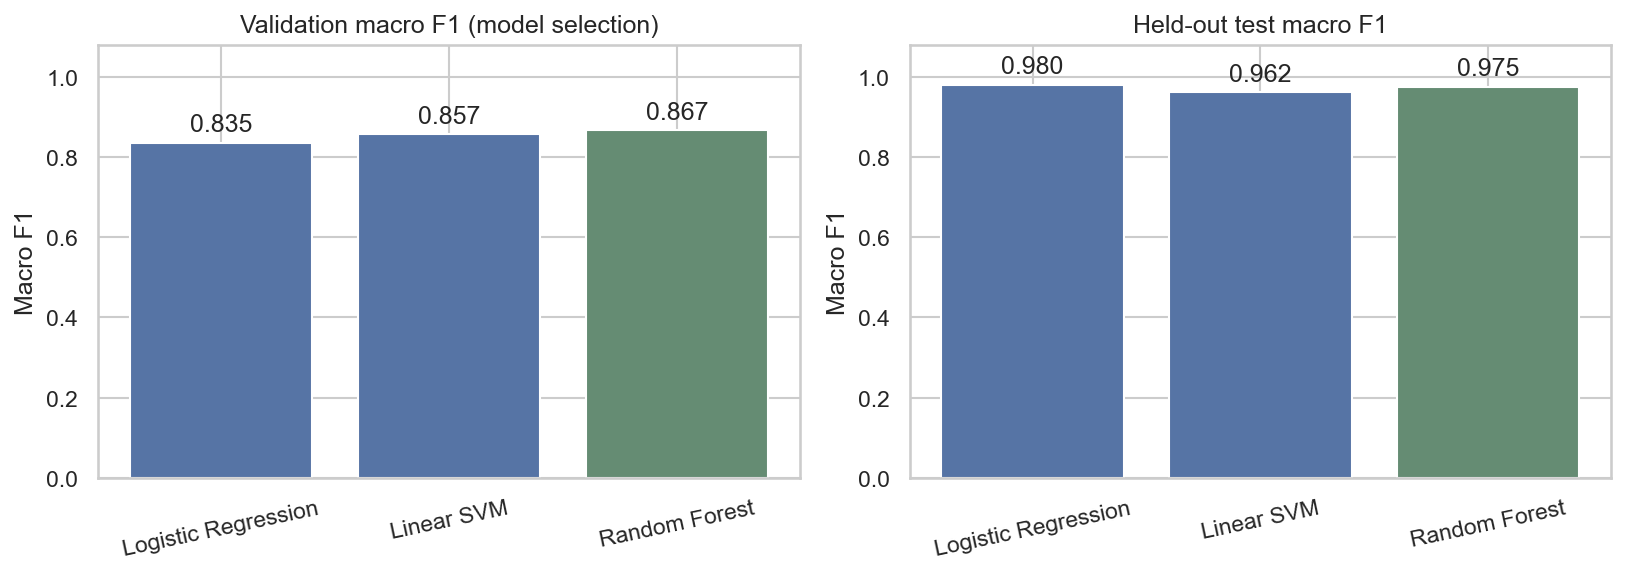

In [8]:
display(comparison[['display_name', 'validation_macro_f1', 'test_accuracy', 'test_macro_precision', 'test_macro_recall', 'test_macro_f1', 'selected_baseline']])
print('Most-frequent-class dummy test metrics:', run['dummy_test_metrics'])
display(Image(filename=str(REPORTS / 'figures' / 'model_comparison.png')))

## 7. Selected baseline confusion matrix

Rows are source target classes and columns are predicted classes. Every family also has its own CSV and PNG confusion matrix in the report folder.

,antibacterial,anti_inflammatory_nsaid,corticosteroid,antifungal,acid_reducer,antihypertensive
true_class,,,,,,
antibacterial,59,0,3,7,0,0
anti_inflammatory_nsaid,0,64,0,0,0,0
corticosteroid,0,0,64,0,0,0
antifungal,0,0,0,69,0,0
acid_reducer,0,0,0,0,19,0
antihypertensive,0,0,0,0,0,57


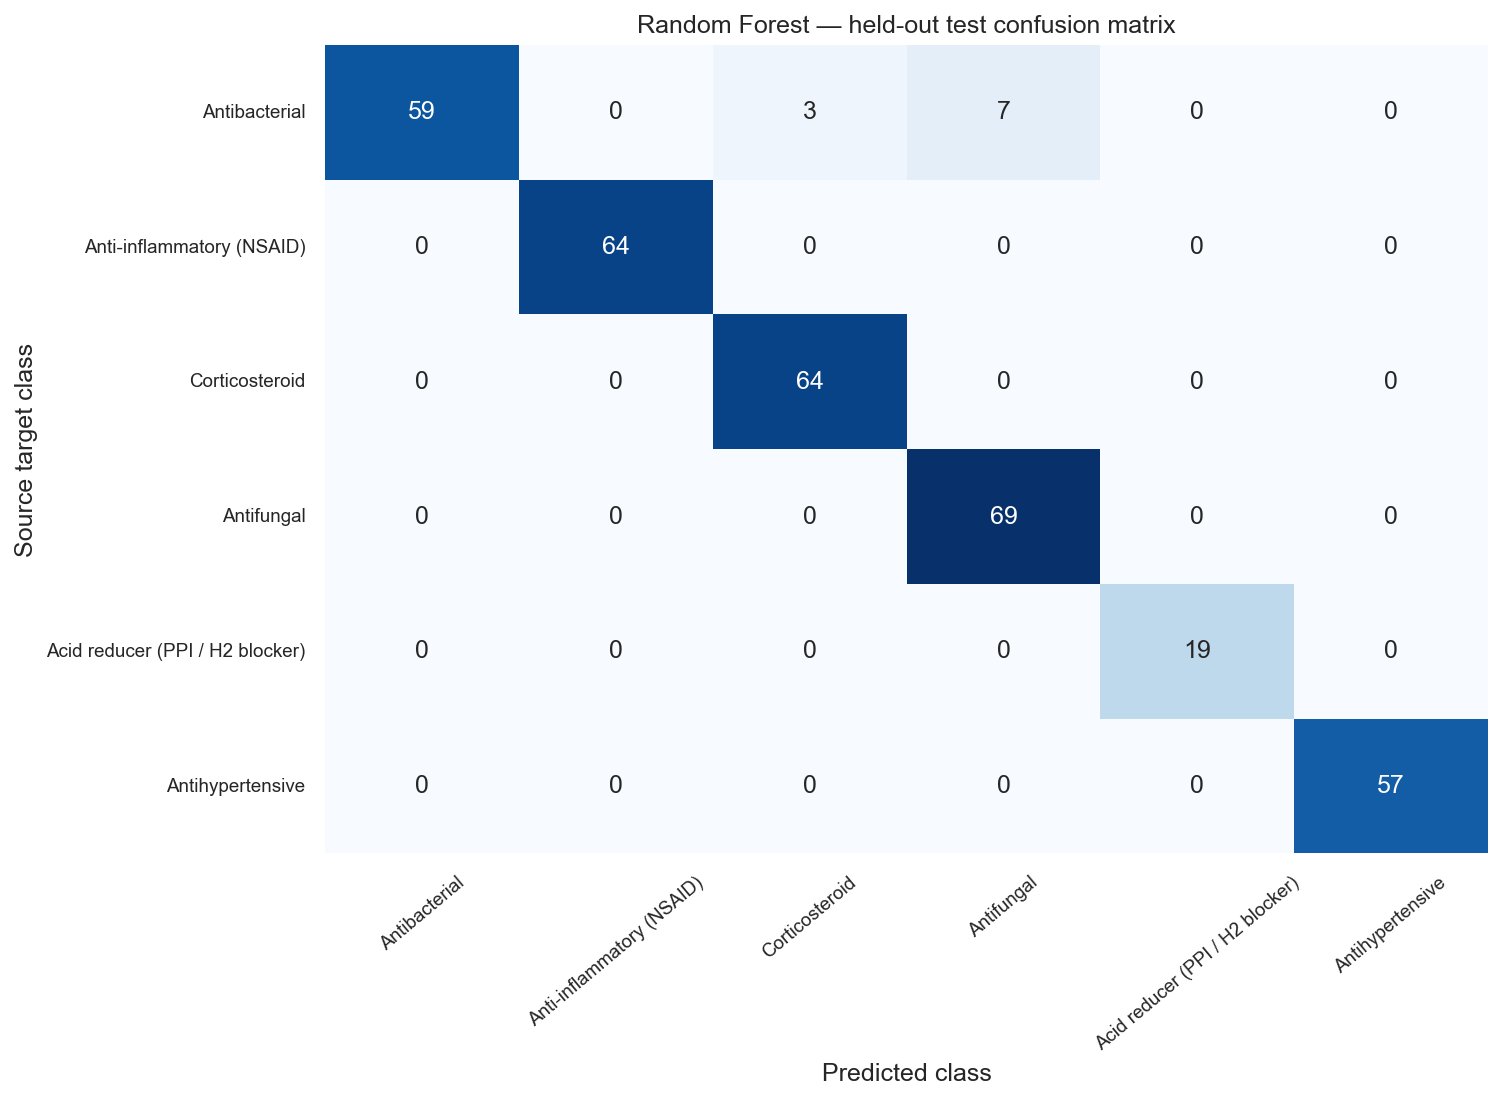

In [9]:
matrix = pd.read_csv(REPORTS / f'confusion_matrix_{selected}.csv', index_col=0)
display(matrix)
display(Image(filename=str(REPORTS / 'figures' / f'confusion_matrix_{selected}.png')))

In [10]:
per_class = pd.read_csv(REPORTS / 'per_class_test_metrics.csv')
display(per_class.loc[per_class.model.eq(selected)].drop(columns='model'))
print('Class supports are document counts; groups show the independent evaluation components.')

,class_label,precision,recall,f1,support,groups
12,antibacterial,1.000000,0.855072,0.921875,69,5
13,anti_inflammatory_nsaid,1.000000,1.000000,1.000000,64,2
14,corticosteroid,0.955224,1.000000,0.977099,64,2
15,antifungal,0.907895,1.000000,0.951724,69,2
16,acid_reducer,1.000000,1.000000,1.000000,19,2
17,antihypertensive,1.000000,1.000000,1.000000,57,3


Class supports are document counts; groups show the independent evaluation components.


## 8. Repeated-label weighting

Group-balanced metrics give each test component total weight one. Repackager labels therefore do not receive extra weight just because a family has more documents. Document-level and component-balanced results answer different aggregation questions; both are included for review. The test set contains only 15 components, so these estimates describe the selected snapshot.

In [11]:
display(comparison[['display_name', 'test_accuracy', 'test_macro_f1', 'test_group_balanced_accuracy', 'test_group_balanced_macro_f1']])
print('Independent test components:', run['partition_groups']['test'])

,display_name,test_accuracy,test_macro_f1,test_group_balanced_accuracy,test_group_balanced_macro_f1
0,Logistic Regression,0.976608,0.979940,0.911111,0.932692
1,Linear SVM,0.956140,0.962192,0.955556,0.964286
2,Random Forest,0.970760,0.975116,0.962963,0.968761


Independent test components: 15


## 9. Source-linked error analysis

Errors retain record IDs, generic names, and source links for inspection. Targets are automatically derived from EPC metadata; they are not expert-adjudicated drug indications. Combination labels can require careful interpretation of the target scheme.

In [12]:
errors = pd.read_csv(REPORTS / 'test_errors.csv')
print('Test errors per model:')
display(errors.groupby('model').size().rename('errors'))
display(errors.loc[errors.model.eq(selected), ['record_id', 'generic_names', 'true_class', 'predicted_class', 'source_url']])

Test errors per model:


model
linear_svm             15
logistic_regression     8
random_forest          10
Name: errors, dtype: int64

,record_id,generic_names,true_class,predicted_class,source_url
23,38f21173-d355-80a7-e063-6294a90a3643,"[""TOBRAMYCIN SOLUTION""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=9d8b7b6c-3072-48e9-87c8-51160...
24,459f9e6a-cdbc-32cb-e063-6294a90a03e3,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=e8205898-0162-4e6c-bcf1-87cb0...
25,468bc4c2-5d73-2339-e063-6394a90ad327,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=f2f8bf02-57f8-4d34-937a-32411...
26,48d4400d-e246-f109-e063-6394a90a8103,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=75df79e9-f064-4f46-9837-8d4d5...
27,68bf90c8-847a-4ea3-8855-c7b380f994dd,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=5563e8af-c6c9-42a2-974d-7d364...
28,98c53b08-1ee0-42d8-89a7-1443b7a7f440,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=7803ac83-1250-451b-8ad8-2c0a3...
29,a6d68829-f7b6-4b9b-ad44-110c47609918,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=a6d68829-f7b6-4b9b-ad44-110c4...
30,abdb1d21-5989-4e31-8036-18a82673eaad,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=6a3c3871-1d3a-44d6-8be3-526b3...
31,d34d6f39-c5c7-40ea-89da-977c6e1eaa05,"[""LOTEPREDNOL ETABONATE AND TOBRAMYCIN""]",antibacterial,corticosteroid,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=7c752fac-8ec8-49ab-8570-09d2a...
32,e6e150b5-807d-425e-96f8-345c2a56ee8e,"[""TOBRAMYCIN""]",antibacterial,antifungal,https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=fd871ae7-9083-4e57-aacb-f584c...


## 10. Feature inspection

Linear models expose class coefficients. Random Forest exposes global feature importance, rather than class-specific coefficients. These are model diagnostics, not medical recommendations or calibrated confidence scores.

In [13]:
top = pd.read_csv(REPORTS / 'top_features.csv')
display(top.loc[top.model.eq(selected)].head(20))

,model,class_label,term,weight,weight_type
180,random_forest,all_classes,the chance,0.006069,global_feature_importance
181,random_forest,all_classes,hypotension,0.005330,global_feature_importance
182,random_forest,all_classes,antifungal,0.005299,global_feature_importance
183,random_forest,all_classes,nsaids,0.005259,global_feature_importance
184,random_forest,all_classes,aspirin,0.004260,global_feature_importance
185,random_forest,all_classes,or later,0.004109,global_feature_importance
186,random_forest,all_classes,ulcers or,0.004095,global_feature_importance
187,random_forest,all_classes,diastolic,0.003986,global_feature_importance
188,random_forest,all_classes,pressure heart,0.003614,global_feature_importance
189,random_forest,all_classes,nsaids aspirin,0.003613,global_feature_importance


## 11. Load the model and classify a real document

The following demonstration uses a source-backed held-out acid-reducer label from the already reported experiment. Only its text is passed to the classifier. It also saves the complete text and its provenance under `data/examples/` so the command-line classifier can be tried with the same document.

In [14]:
df = pd.read_parquet(ROOT / 'data' / 'processed' / 'medicine_labels.parquet').merge(assignments[['record_id', 'split']], on='record_id', validate='one_to_one')
example = df.loc[df.split.eq('test') & df.class_label.eq('acid_reducer')].sort_values(['word_count', 'record_id']).iloc[0]
model_path = ROOT / 'models' / 'phase2' / 'benchmark.joblib'
bundle = load_baseline(model_path)
result = classify_text(model_path, example.document_text)
display(pd.Series({'generic_names': example.generic_names, 'source_target': example.class_label, 'predicted_class': result['predicted_class'], 'source_url': example.source_url}))
print('Fitted partitions:', bundle['fitted_partitions'])
print('Document excerpt:', example.document_text[:600])
examples = ROOT / 'data' / 'examples'
examples.mkdir(parents=True, exist_ok=True)
(examples / 'phase2_demo_leaflet.txt').write_text(example.document_text, encoding='utf-8')
write_json(examples / 'phase2_demo_leaflet.json', {'record_id': example.record_id, 'source': 'openFDA', 'source_url': example.source_url, 'class_label': example.class_label, 'is_synthetic': False, 'dataset_sha256': run['dataset_sha256']})
print('Saved real example: data/examples/phase2_demo_leaflet.txt')

generic_names                                                           ["ESOMEPRAZOLE MAGNESIUM DIHYDRATE"]
source_target                                                                                   acid_reducer
predicted_class                                                                                 acid_reducer
source_url         https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=29eb7b87-59a4-4d27-ad53-789da...
dtype: object

Fitted partitions: ['train', 'validation']
Document excerpt: Indications And Usage
Uses • treats frequent heartburn (occurs 2 or more days a week) • not intended for immediate relief of heartburn; this drug may take 1 to 4 days for full effect

Purpose
Purpose Acid reducer

Dosage And Administration
Directions • adults 18 years of age and older • this product is to be used once a day (every 24 hours), every day for 14 days • may take 1 to 4 days for full effect 14-Day Course of Treatment • swallow 1 capsule with a glass of water before eating in the morning • take every day for 14 days • do not take more than 1 capsule a day • swallow whole. Do not crus
Saved real example: data/examples/phase2_demo_leaflet.txt


## 12. Verification and checkpoint

The experiment checks whole-group isolation, all-class fold coverage, source/split/reference hashes, the pre-test selection snapshot, final TF-IDF vocabulary/IDF fitted without test text, standalone artifacts, frozen parameters, metric recomputation, and confusion matrices. Software tests separately exercise training-fold vocabulary leakage, persistence, exact ingredient matching, and group-weighting behavior.

In [15]:
verification = json.loads((REPORTS / 'validation.json').read_text(encoding='utf-8'))
assert verification['all_passed']
assert verification['selected_model'] == selected
print('Passed experiment checks:', len(verification['checks']))
display(pd.DataFrame(verification['checks'])[['name', 'passed']])
print('Phase 2 is ready for review. The next phase awaits approval.')

Passed experiment checks: 75


,name,passed
0,all_documents_accounted_for,True
1,three_partitions,True
2,benchmark_groups_disjoint,True
3,phase1_groups_preserved,True
4,all_classes_in_each_partition,True
...,...,...
70,output_checksum_predictions_validation.csv,True
71,output_checksum_rxnorm_matches.csv,True
72,output_checksum_split_class_balance.csv,True
73,output_checksum_test_errors.csv,True


Phase 2 is ready for review. The next phase awaits approval.


## Stop for Phase 2 review

Read `reports/phase_2_review.md` and review the selected benchmark, validation/test comparison, class supports, group-aware CV variation, source-linked errors, and `docs/baseline_model_card.md`.

After review, Phase 3 will implement a PyTorch LSTM or 1D-CNN and compare it on the same frozen evaluation split. Later models should tune on training/validation data.

Data provided by the U.S. Food and Drug Administration (https://open.fda.gov). This product uses publicly available data from the U.S. National Library of Medicine (NLM), National Institutes of Health, Department of Health and Human Services; NLM is not responsible for the product and does not endorse or recommend this or any other product.